<a href="https://colab.research.google.com/github/marques-tech/classificador-exercicios-pytorch/blob/main/classificador_exercicios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
Tesla T4


In [2]:
!pip install -q datasets
from datasets import load_dataset

ds = load_dataset("averrous/workout")
print(ds)

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 9687
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 2763
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 1403
    })
})


['barbell biceps curl', 'bench press', 'chest fly machine', 'deadlift', 'decline bench press', 'hammer curl', 'hip thrust', 'incline bench press', 'lat pulldown', 'lateral raises', 'leg extension', 'leg raises', 'plank', 'pull up', 'push up', 'romanian deadlift', 'russian twist', 'shoulder press', 'squat', 't bar row', 'tricep dips', 'tricep pushdown']


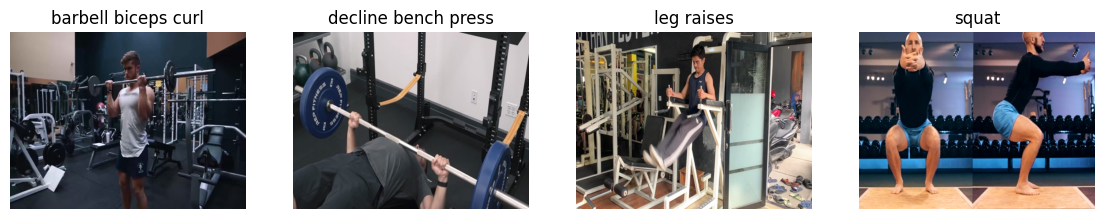

In [3]:
import matplotlib.pyplot as plt

nomes = ds["train"].features["label"].names
print(nomes)

indices = [0, 2000, 5000, 8000]

fig, eixos = plt.subplots(1, 4, figsize=(14, 4))
for ax, i in zip(eixos, indices):
    exemplo = ds["train"][i]
    ax.imshow(exemplo["image"])
    ax.set_title(nomes[exemplo["label"]])
    ax.axis("off")
plt.show()

In [4]:
import torch
from torchvision import transforms
from torch.utils.data import DataLoader

transformacao = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

def preparar(lote):
    lote["pixel_values"] = [transformacao(img.convert("RGB")) for img in lote["image"]]
    return lote

ds.set_transform(preparar)

def juntar(lote):
    imagens = torch.stack([x["pixel_values"] for x in lote])
    rotulos = torch.tensor([x["label"] for x in lote])
    return imagens, rotulos

treino = DataLoader(ds["train"], batch_size=32, shuffle=True, collate_fn=juntar)
validacao = DataLoader(ds["validation"], batch_size=32, collate_fn=juntar)
teste = DataLoader(ds["test"], batch_size=32, collate_fn=juntar)

imagens, rotulos = next(iter(treino))
print(imagens.shape, rotulos.shape)

torch.Size([32, 3, 224, 224]) torch.Size([32])


In [5]:
import torch.nn as nn
from torchvision import models

dispositivo = torch.device("cuda")

modelo = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for parametro in modelo.parameters():
    parametro.requires_grad = False

modelo.fc = nn.Linear(modelo.fc.in_features, 22)
modelo = modelo.to(dispositivo)

criterio = nn.CrossEntropyLoss()
otimizador = torch.optim.Adam(modelo.fc.parameters(), lr=0.001)

print("Modelo pronto!")

Modelo pronto!


Época 1/10 | perda: 1.418 | acurácia validação: 86.9%
Época 2/10 | perda: 0.544 | acurácia validação: 91.5%
Época 3/10 | perda: 0.364 | acurácia validação: 93.6%
Época 4/10 | perda: 0.276 | acurácia validação: 95.2%
Época 5/10 | perda: 0.217 | acurácia validação: 95.2%
Época 6/10 | perda: 0.188 | acurácia validação: 95.8%
Época 7/10 | perda: 0.162 | acurácia validação: 96.5%
Época 8/10 | perda: 0.139 | acurácia validação: 96.6%
Época 9/10 | perda: 0.123 | acurácia validação: 96.6%
Época 10/10 | perda: 0.111 | acurácia validação: 96.4%


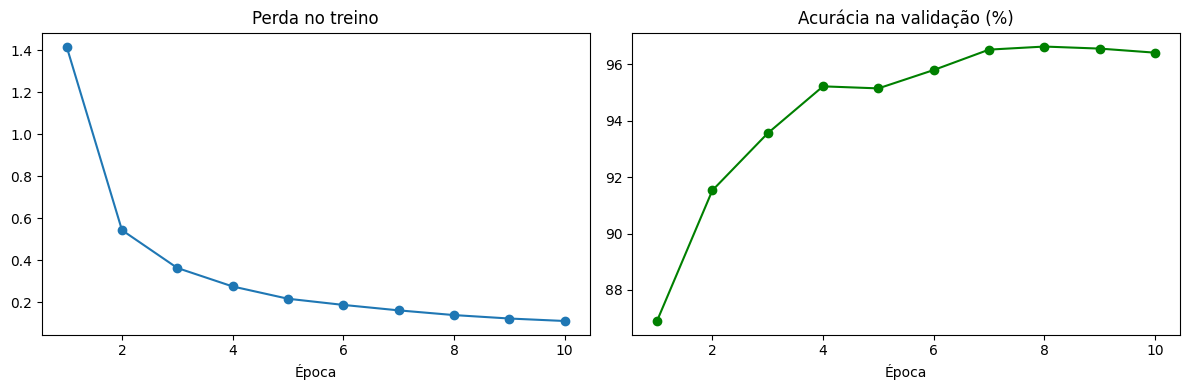

Melhor época na validação: 8


In [6]:
import matplotlib.pyplot as plt

epocas = 10
hist_perda = []
hist_acuracia = []

for epoca in range(epocas):
    modelo.train()
    perda_total = 0
    for imagens, rotulos in treino:
        imagens, rotulos = imagens.to(dispositivo), rotulos.to(dispositivo)
        otimizador.zero_grad()
        saidas = modelo(imagens)
        perda = criterio(saidas, rotulos)
        perda.backward()
        otimizador.step()
        perda_total += perda.item()

    modelo.eval()
    acertos = 0
    total = 0
    with torch.no_grad():
        for imagens, rotulos in validacao:
            imagens, rotulos = imagens.to(dispositivo), rotulos.to(dispositivo)
            previsoes = modelo(imagens).argmax(dim=1)
            acertos += (previsoes == rotulos).sum().item()
            total += rotulos.size(0)

    perda_media = perda_total / len(treino)
    acuracia = 100 * acertos / total
    hist_perda.append(perda_media)
    hist_acuracia.append(acuracia)
    print(f"Época {epoca+1}/{epocas} | perda: {perda_media:.3f} | acurácia validação: {acuracia:.1f}%")

fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
x = range(1, epocas + 1)

eixos[0].plot(x, hist_perda, marker="o")
eixos[0].set_title("Perda no treino")
eixos[0].set_xlabel("Época")

eixos[1].plot(x, hist_acuracia, marker="o", color="green")
eixos[1].set_title("Acurácia na validação (%)")
eixos[1].set_xlabel("Época")

plt.tight_layout()
plt.show()

melhor = hist_acuracia.index(max(hist_acuracia)) + 1
print(f"Melhor época na validação: {melhor}")

In [7]:
modelo.eval()
acertos = 0
total = 0
with torch.no_grad():
    for imagens, rotulos in teste:
        imagens, rotulos = imagens.to(dispositivo), rotulos.to(dispositivo)
        previsoes = modelo(imagens).argmax(dim=1)
        acertos += (previsoes == rotulos).sum().item()
        total += rotulos.size(0)

print(f"Acurácia no teste: {acertos/total:.1%}")

Acurácia no teste: 96.4%


In [8]:
torch.save(modelo.state_dict(), "modelo_exercicios.pth")
print("Modelo salvo!")

Modelo salvo!
